In [1]:
# Project Title : Amazon Sales EDA

In [2]:
# Objective :
# Analyse Amazon sales orders (March to June 2022) to
# understand revenue, customers, logistics, products and cancellations,
# and give recommendations for growth.

In [3]:
# Themes :
# Financial | Customer | Logistics | Product | Returns

In [4]:
# Importing libraries: pandas/numpy for data, matplotlib/seaborn for charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# Loading the dataset from Drive and checking its size
df = pd.read_csv('/content/drive/MyDrive/Jobaaj learning Assignments /Data Analytics Exam 1 (Assignment)/sales_dataset.csv')
df.shape

/tmp/ipykernel_3913/3381043952.py:2: DtypeWarning: Columns (22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/Jobaaj learning Assignments /Data Analytics Exam 1 (Assignment)/sales_dataset.csv')


(128949, 23)

In [7]:
# First 5 rows: checking date format and range
df.head()

,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,S,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,3XL,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,XL,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,L,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,3XL,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [8]:
# Last 5 rows: checking date format and range
df.tail()

,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
128944,406-6001380-7673107,05-31-22,Shipped,Amazon,Amazon.in,Expedited,JNE3697,JNE3697-KR-XL,kurta,XL,...,INR,517.0,HYDERABAD,TELANGANA,500013.0,IN,NaN,False,NaN,False
128945,402-9551604-7544318,05-31-22,Cancelled,Amazon,Amazon.in,Expedited,SET401,SET401-KR-NP-M,Set,M,...,INR,999.0,GURUGRAM,HARYANA,122004.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,False
128946,407-9547469-3152358,05-31-22,Shipped,Amazon,Amazon.in,Expedited,J0157,J0157-DR-XXL,Western Dress,XXL,...,INR,690.0,HYDERABAD,TELANGANA,500049.0,IN,NaN,False,NaN,False
128947,402-6184140-0545956,05-31-22,Shipped,Amazon,Amazon.in,Expedited,J0012,J0012-SKD-XS,Set,XS,...,INR,1199.0,Halol,Gujarat,389350.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,False
128948,408-7436540-8728312,05-31-22,Shipped,Amazon,Amazon.in,Expedited,J0003,J0003-SET-S,Set,S,...,INR,696.0,Raipur,CHHATTISGARH,492014.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,False,NaN,False


In [9]:
# Structure: column names, data types, non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128949 entries, 0 to 128948
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Order ID            128949 non-null  object 
 1   Date                128949 non-null  object 
 2   Status              128949 non-null  object 
 3   Fulfilment          128949 non-null  object 
 4   Sales Channel       128949 non-null  object 
 5   ship-service-level  128949 non-null  object 
 6   Style               128949 non-null  object 
 7   SKU                 128949 non-null  object 
 8   Category            128949 non-null  object 
 9   Size                128949 non-null  object 
 10  ASIN                128949 non-null  object 
 11  Courier Status      122078 non-null  object 
 12  Qty                 128949 non-null  int64  
 13  currency            121155 non-null  object 
 14  Amount              121155 non-null  float64
 15  ship-city           128916 non-nul

### Observations from df.info()
- The dataset has 128,949 rows and 23 columns (memory about 21.8 MB).
- Date is stored as text (object), so it needs converting to datetime in the cleaning step.
- Amount and currency each have 7,794 missing values (about 6%). Amount will be filled with the median.
- Courier Status has 6,871 missing values (about 5.3%).
- ship-city, ship-state, ship-country and ship-postal-code have only 33 missing values each, which is negligible.
- promotion-ids (about 38% missing) and fulfilled-by (about 70% missing) are mostly blank, which likely means "no promotion" or "not fulfilled by Easy Ship". These will be filled with a label, not dropped.
- ship-postal-code is stored as a float, but it is an identifier, so it should be converted to text.
- Unnamed: 22 is an unlabeled column that is not in the data dictionary. It looks like junk and will be reviewed and dropped in the cleaning step.
- Qty (int), Amount (float) and B2B (bool) already have suitable types.

In [10]:
# What does Unnamed: 22 contain?
df["Unnamed: 22"].value_counts(dropna=False).head(10)

,count
Unnamed: 22,
False,79908
NaN,49041


In [11]:
# Result: Unnamed: 22 holds only False (79,908 rows) or blank (49,041 rows).
# It carries no information, so it’s junk and safe to drop.
df.drop(columns=['Unnamed: 22'], inplace=True)
df.shape

(128949, 22)

Unnamed: 22 had no label and held only False or blank values, so it adds nothing to the analysis. Dropped.

In [12]:
# Some column names had trailing spaces, which caused a KeyError. I stripped the spaces from all column names.
df.columns.tolist()

['Order ID',
 'Date',
 'Status',
 'Fulfilment',
 'Sales Channel ',
 'ship-service-level',
 'Style',
 'SKU',
 'Category',
 'Size',
 'ASIN',
 'Courier Status',
 'Qty',
 'currency',
 'Amount',
 'ship-city',
 'ship-state',
 'ship-postal-code',
 'ship-country',
 'promotion-ids',
 'B2B',
 'fulfilled-by']

In [13]:
# Removing extra spaces from column names so they can be called reliably
df.columns = df.columns.str.strip()
df.columns.tolist()

['Order ID',
 'Date',
 'Status',
 'Fulfilment',
 'Sales Channel',
 'ship-service-level',
 'Style',
 'SKU',
 'Category',
 'Size',
 'ASIN',
 'Courier Status',
 'Qty',
 'currency',
 'Amount',
 'ship-city',
 'ship-state',
 'ship-postal-code',
 'ship-country',
 'promotion-ids',
 'B2B',
 'fulfilled-by']

In [14]:
# Columns with one value in every row add nothing to the analysis
for col in ['Sales Channel', 'currency', 'ship-country'] :
  print(col, '->', df[col].unique())

Sales Channel -> ['Amazon.in' 'Non-Amazon']
currency -> ['INR' nan]
ship-country -> ['IN' nan]


In [15]:
# currency has only INR and ship-country has only IN, so they add nothing to the analysis
df.drop(columns=['currency', 'ship-country'], inplace=True)
df.shape

(128949, 20)

Sales Channel has two values, so I kept it. currency (INR) and ship-country (IN) are constant, so I dropped them.

In [16]:
# Finding Date values that are not in the expected MM-DD-YY format (8 characters)
bad_dates = df[df['Date'].str.len() !=8]
print(len(bad_dates))
bad_dates[['Order ID', 'Date', 'Status']].head(10)

55097


,Order ID,Date,Status
29916,405-6163095-9509124,04-12-2022,Shipped
29917,403-2229855-3541155,04-12-2022,Shipped
29918,171-1029312-3038738,04-12-2022,Shipped - Delivered to Buyer
29919,408-5086595-1206718,04-12-2022,Shipped - Delivered to Buyer
29920,405-2183842-2225946,04-12-2022,Shipped
29921,171-1641533-8921966,04-12-2022,Shipped
29922,404-7490807-6300351,04-12-2022,Shipped
29923,404-9177043-8241922,04-12-2022,Shipped
29924,171-2527471-9384325,04-12-2022,Shipped
29925,406-9484837-7730728,04-12-2022,Cancelled


In [17]:
# Date has two formats mixed together, so parsing each one separately and combining them
d1 = pd.to_datetime(df['Date'], format='%m-%d-%y', errors='coerce')
d2 = pd.to_datetime(df['Date'], format='%m-%d-%Y', errors='coerce')
df['Date'] = d1.fillna(d2)

print('Unparsed dates:', df['Date'].isnull().sum())
print(df['Date'].min(), '->', df['Date'].max())

Unparsed dates: 0
2022-03-31 00:00:00 -> 2022-06-29 00:00:00


In [18]:
# Postal code is an identifier, so storing it as text; low-cardinality columns become category
df['ship-postal-code'] = df['ship-postal-code'].astype('Int64').astype('string')
for col in ['Status', 'Fulfilment', 'ship-service-level', 'Category', 'Size', 'Courier Status']:
    df[col] = df[col].astype('category')
df.dtypes

,0
Order ID,object
Date,datetime64[ns]
Status,category
Fulfilment,category
Sales Channel,object
ship-service-level,category
Style,object
SKU,object
Category,category
Size,category


Postal code is an identifier, not a quantity, so I stored it as text. Status, Fulfilment, ship-service-level, Category, Size and Courier Status have few distinct values, so I converted them to category to save memory.
All the types are now correct.

In [19]:
# Summary statistics for Qty and Amount (before any null filling)
df.describe()

,Date,Qty,Amount
count,128949,128949.000000,121155.000000
mean,2022-05-12 11:46:37.636274176,0.904629,648.550806
min,2022-03-31 00:00:00,0.000000,0.000000
25%,2022-04-20 00:00:00,1.000000,449.000000
50%,2022-05-10 00:00:00,1.000000,605.000000
75%,2022-06-04 00:00:00,1.000000,788.000000
max,2022-06-29 00:00:00,15.000000,5584.000000
std,NaN,0.314782,281.218324


Amount is right-skewed: the mean (648.55) is higher than the median (605) and the max (5,584) is much larger than the 75th percentile (788). Because of these outliers, the median is a better fill value than the mean. Qty is mostly 1, with a max of 15. Qty has a minimum of 0, which needs checking against order status.

In [20]:
# Missing values per column, as a percentage
(df.isnull().sum()/len(df)*100).round(2).sort_values(ascending=False)

,0
fulfilled-by,69.55
promotion-ids,38.11
Amount,6.04
Courier Status,5.33
ship-city,0.03
ship-postal-code,0.03
ship-state,0.03
Order ID,0.00
Fulfilment,0.00
Status,0.00


 - fulfilled-by (69.55%) and promotion-ids (38.11%) are mostly blank, but the   blanks carry meaning, so I will fill them with a label, not drop them. Amount (6.04%) and Courier Status (5.33%) have moderate nulls.
- The ship-city, ship-state and postal code nulls are only 0.03%. All other columns are complete.

In [21]:
#Checking which order statuses have missing Amount values
df[df['Amount'].isnull()]['Status'].value_counts()

,count
Status,
Cancelled,7563
Shipped,209
Shipped - Delivered to Buyer,9
Shipping,8
Shipped - Returned to Seller,3
Pending,2
Pending - Waiting for Pick Up,0
Shipped - Damaged,0
Shipped - Lost in Transit,0


In [22]:
# Filling missing Amount with the median, because Amount is right-skewed (mean > median)
median_amount = df['Amount'].median()
df['Amount'] = df['Amount'].fillna(median_amount)
print('median_used:', median_amount )
print('Nulls left in amount:', df['Amount'].isnull().sum())

median_used: 605.0
Nulls left in amount: 0


7,563 of the 7,794 missing Amount values belong to cancelled orders, so the blanks mean no payment was made. As the problem statement asks, I filled them with the median (605), which is better than the mean because Amount is right-skewed. Because the filled values for cancelled orders are not real revenue, **I will exclude cancelled orders when calculating revenue.**

In [23]:
# Blank promotion-ids means no promotion;
# blank fulfilled-by means the order was not fulfilled by Easy Ship
df['promotion-ids'] = df['promotion-ids'].fillna('No promotion')
df['fulfilled-by'] = df['fulfilled-by'].fillna('No easy ship')
print(df['promotion-ids'].isnull().sum(), df['fulfilled-by'].isnull().sum())
df['fulfilled-by'].value_counts()

0 0


,count
fulfilled-by,
No easy ship,89679
Easy Ship,39270


promotion-ids and fulfilled-by were blank because no promotion was applied or the order was not fulfilled by Easy Ship. I filled them with labels instead of dropping them, so no rows are lost and these columns can still be used for analysis.

In [24]:
# Checking which order statuses have missing Courier Status
df[df['Courier Status'].isnull()]['Status'].value_counts()

,count
Status,
Cancelled,6856
Shipped - Delivered to Buyer,11
Shipped - Returned to Seller,3
Shipped,1
Pending,0
Shipped - Damaged,0
Pending - Waiting for Pick Up,0
Shipped - Out for Delivery,0
Shipped - Lost in Transit,0


In [25]:
# Cancelled orders never reached a courier, so blank Courier Status gets the label 'Not Shipped'
df['Courier Status'] = df['Courier Status'].cat.add_categories('Not Shipped')
df['Courier Status'] = df['Courier Status'].fillna('Not Shipped')
print('Nulls left:', df['Courier Status'].isnull().sum())
df['Courier Status'].value_counts()

Nulls left: 0


,count
Courier Status,
Shipped,109463
Not Shipped,6871
Unshipped,6681
Cancelled,5934


6,856 of the 6,871 missing Courier Status values belong to cancelled orders, which never reached a courier. I filled the blanks with
 ‘Not Shipped’ so no rows are lost.

In [26]:
# Looking at the rows with missing shipping location
df[df['ship-city'].isnull()][['Order ID','Status','Fulfilment','ship-city','ship-state', 'ship-postal-code']].head(10)

,Order ID,Status,Fulfilment,ship-city,ship-state,ship-postal-code
1862,404-0566904-4825137,Shipped,Amazon,NaN,NaN,<NA>
1863,404-0566904-4825137,Shipped,Amazon,NaN,NaN,<NA>
8743,406-4003386-8768363,Shipped,Amazon,NaN,NaN,<NA>
11206,402-0107720-7057168,Shipped,Amazon,NaN,NaN,<NA>
13243,407-4532637-8415521,Cancelled,Merchant,NaN,NaN,<NA>
15679,404-9229894-8608305,Shipped,Amazon,NaN,NaN,<NA>
16778,402-4919636-4333150,Shipped - Delivered to Buyer,Merchant,NaN,NaN,<NA>
18342,405-4927647-8064368,Shipped,Amazon,NaN,NaN,<NA>
22921,402-8628677-0457954,Shipped - Returned to Seller,Merchant,NaN,NaN,<NA>
24977,406-4079063-8291520,Cancelled,Amazon,NaN,NaN,<NA>


All three location fields (city, state, postal code) are blank together, and many of these are real shipped orders. Dropping them would remove real sales, so fill them with a label instead. It’s only 33 rows, so it won’t affect the analysis.

In [27]:
# Only 33 rows have no shipping location; filling with 'unknown' keeps their sales in the data
for col in ['ship-city', 'ship-state', 'ship-postal-code']:
  df[col] = df[col].fillna('unknown')
print(df[['ship-city', 'ship-state', 'ship-postal-code']].isnull().sum())

ship-city           0
ship-state          0
ship-postal-code    0
dtype: int64


# Column                                        How it was handled
# Amount                                        Filled with the median (605)
# promotion-ids                                 Filled with “No promotion”
# fulfilled-by                                  Filled with “No easy ship”
# Courier Status                                Filled with “Not Shipped”
# ship-city, ship-state, ship-postal-code       Filled with “unknown”

In [28]:
# Final check: total missing values left in the dataset
print('Total nulls left:', df.isnull().sum())

Total nulls left: Order ID              0
Date                  0
Status                0
Fulfilment            0
Sales Channel         0
ship-service-level    0
Style                 0
SKU                   0
Category              0
Size                  0
ASIN                  0
Courier Status        0
Qty                   0
Amount                0
ship-city             0
ship-state            0
ship-postal-code      0
promotion-ids         0
B2B                   0
fulfilled-by          0
dtype: int64


All missing values are handled: Amount with the median, and the blank-means-something columns with labels. No rows were dropped.

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128949 entries, 0 to 128948
Data columns (total 20 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Order ID            128949 non-null  object        
 1   Date                128949 non-null  datetime64[ns]
 2   Status              128949 non-null  category      
 3   Fulfilment          128949 non-null  category      
 4   Sales Channel       128949 non-null  object        
 5   ship-service-level  128949 non-null  category      
 6   Style               128949 non-null  object        
 7   SKU                 128949 non-null  object        
 8   Category            128949 non-null  category      
 9   Size                128949 non-null  category      
 10  ASIN                128949 non-null  object        
 11  Courier Status      128949 non-null  category      
 12  Qty                 128949 non-null  int64         
 13  Amount              128949 no

# Handling duplicates

In [30]:
# Checking for fully duplicated rows
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 6


In [31]:
# Viewing the duplicated rows before removing them
df[df.duplicated(keep=False)].sort_values('Order ID')

,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,ASIN,Courier Status,Qty,Amount,ship-city,ship-state,ship-postal-code,promotion-ids,B2B,fulfilled-by
85781,171-3249942-2207542,2022-05-03,Shipped,Amazon,Amazon.in,Expedited,SET323,SET323-KR-NP-XL,Set,XL,B09NDKKM7P,Shipped,1,939.0,PUNE,MAHARASHTRA,411057,IN Core Free Shipping 2015/04/08 23-48-5-108,False,No easy ship
85782,171-3249942-2207542,2022-05-03,Shipped,Amazon,Amazon.in,Expedited,SET323,SET323-KR-NP-XL,Set,XL,B09NDKKM7P,Shipped,1,939.0,PUNE,MAHARASHTRA,411057,IN Core Free Shipping 2015/04/08 23-48-5-108,False,No easy ship
79835,171-9628368-5329958,2022-05-07,Cancelled,Amazon,Amazon.in,Expedited,J0329,J0329-KR-L,kurta,L,B09KXRB7JV,Cancelled,0,605.0,ERNAKULAM,KERALA,682017,No promotion,False,No easy ship
79836,171-9628368-5329958,2022-05-07,Cancelled,Amazon,Amazon.in,Expedited,J0329,J0329-KR-L,kurta,L,B09KXRB7JV,Cancelled,0,605.0,ERNAKULAM,KERALA,682017,No promotion,False,No easy ship
86409,405-8669298-3850736,2022-05-03,Shipped,Amazon,Amazon.in,Expedited,MEN5025,MEN5025-KR-XXXL,kurta,3XL,B08YYQS8FH,Shipped,1,533.0,GHAZIABAD,UTTAR PRADESH,201010,IN Core Free Shipping 2015/04/08 23-48-5-108,False,No easy ship
86410,405-8669298-3850736,2022-05-03,Shipped,Amazon,Amazon.in,Expedited,MEN5025,MEN5025-KR-XXXL,kurta,3XL,B08YYQS8FH,Shipped,1,533.0,GHAZIABAD,UTTAR PRADESH,201010,IN Core Free Shipping 2015/04/08 23-48-5-108,False,No easy ship
30651,406-0372545-6086735,2022-04-12,Cancelled,Amazon,Amazon.in,Expedited,SET197,SET197-KR-NP-L,Set,L,B08B3YPD63,Cancelled,0,605.0,Siliguri,WEST BENGAL,734008,No promotion,False,No easy ship
30652,406-0372545-6086735,2022-04-12,Cancelled,Amazon,Amazon.in,Expedited,SET197,SET197-KR-NP-L,Set,L,B08B3YPD63,Cancelled,0,605.0,Siliguri,WEST BENGAL,734008,No promotion,False,No easy ship
98945,407-4853873-4978725,2022-06-22,Shipped,Amazon,Amazon.in,Expedited,J0230,J0230-SKD-M,Set,M,B08XNJG8B1,Shipped,1,1163.0,Zirakpur,Punjab,140603,IN Core Free Shipping 2015/04/08 23-48-5-108,False,No easy ship
98946,407-4853873-4978725,2022-06-22,Shipped,Amazon,Amazon.in,Expedited,J0230,J0230-SKD-M,Set,M,B08XNJG8B1,Shipped,1,1163.0,Zirakpur,Punjab,140603,IN Core Free Shipping 2015/04/08 23-48-5-108,False,No easy ship


In [32]:
# These 6 rows are exact copies (same order, SKU, size, amount, city), so keeping the first and dropping the repeat
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print('Duplicate rows left:', df.duplicated().sum())
print('shape', df.shape)

Duplicate rows left: 0
shape (128943, 20)


I found 6 fully duplicated rows, with the same order, SKU, size, amount and location, in consecutive positions. They look like accidental double entries, so I kept the first copy and dropped the rest. Repeated Order IDs with different items are normal, so I did not treat those as duplicates.

**Feature creation, starting with the date features.**

In [33]:
# Creating month, month name and weekday from Date for trend analysis
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.month_name()
df['Weekday'] = df['Date'].dt.day_name()
df[['Date', 'Month', 'Month_Name', 'Weekday']].head()

,Date,Month,Month_Name,Weekday
0,2022-04-30,4,April,Saturday
1,2022-04-30,4,April,Saturday
2,2022-04-30,4,April,Saturday
3,2022-04-30,4,April,Saturday
4,2022-04-30,4,April,Saturday


I created Month, Month_Name and Weekday from Date so I can study monthly revenue trends and which days get the most orders.

In [34]:
# Order_Type makes B2B vs B2C readable in charts; Is_Cancelled lets me exclude cancelled orders from revenue
df['Order_Type'] = np.where(df['B2B'] == True, 'B2B', 'B2C')
df['Is_Cancelled'] = df['Status'] == 'Cancelled'
print(df['Order_Type'].value_counts())
print(df['Is_Cancelled'].value_counts())

Order_Type
B2C    128072
B2B       871
Name: count, dtype: int64
Is_Cancelled
False    110605
True      18338
Name: count, dtype: int64


In [35]:
# IS_Returned marks orders where the product came back or the buyer refused it
returned_status = ['Shipped - Returned to Seller', 'Shipped - Returning to Seller', 'Shipped - Rejected by Buyer']
df['IS_Returned'] = df['Status'].isin(returned_status)
print(df['IS_Returned'].value_counts())

IS_Returned
False    126834
True       2109
Name: count, dtype: int64


# **Financial analysis, first the headline numbers.**

In [36]:
# Revenue is calculated only on non-cancelled orders, because cancelled orders brought in no money
sales = df[~(df['Is_Cancelled'])]

total_revenue = sales['Amount'].sum()
total_orders = sales['Order ID'].nunique()
aov = total_revenue / total_orders

print(f'Total Revenue: {total_revenue:,.0f}')
print(f'Total orders: {total_orders:,}')
print(f'Average order value:{aov:,.2f}')






Total Revenue: 71,786,174
Total orders: 103,158
Average order value:695.89


# All amounts are in Indian Rupees (INR). Revenue was calculated on non-cancelled orders only, since no payment was made on cancelled ones.
# Total revenue is about 7.18 crore from 103,158 orders, with an average order value of about 696.

In [37]:
# Monthly revenue and orders (non-cancelled only), to see whether sales are growing
monthly = sales.groupby(['Month', 'Month_Name']).agg(
    Revenue=('Amount', 'sum'),
    Orders=('Order ID', 'nunique')
).reset_index()

print(monthly)

   Month Month_Name      Revenue  Orders
0      3      March     95415.00     140
1      4      April  26284149.62   39121
2      5        May  23986391.00   33725
3      6       June  21420218.00   30172


# revenue by month. The question this answers: is revenue growing?

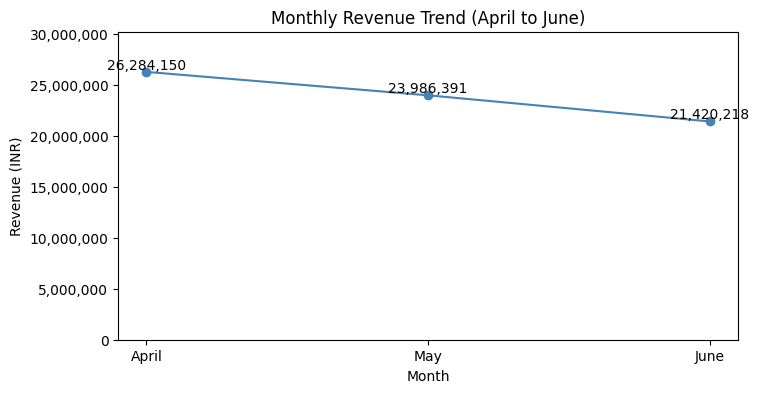

In [38]:
# Line chart for the monthly revenue trend (March is excluded because it has one day only)
trend = monthly[monthly['Month'] != 3]

plt.figure(figsize=(8, 4))
plt.plot(trend['Month_Name'], trend['Revenue'], marker='o', color='steelblue')
for x, y in zip(trend['Month_Name'], trend['Revenue']):
    plt.text(x, y, f'{y:,.0f}', ha='center', va='bottom')
plt.title('Monthly Revenue Trend (April to June)')
plt.xlabel('Month')
plt.ylabel('Revenue (INR)')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.ylim(0, trend['Revenue'].max() * 1.15)
plt.show()

Revenue fell steadily: April 26.28M → May 23.99M (-8.7%) → June 21.42M (-10.7%), about 18.5% lower overall. Orders fell about 22.9% (39,121 → 30,172).
June has only 29 days of data, so per day the drop is about 15.7% (876K/day in April vs 739K/day in June). The decline is real, but slightly smaller than the raw figure.
Average order value stayed stable (about 672 in April, 710 in June), so the fall comes from fewer orders, not smaller baskets.
March is excluded because it has only 1 day of data. With 3 months of data, true seasonality can't be judged.

**best-selling categories. The question this answers: which categories bring in the most revenue?**

In [39]:
# Revenue, units and orders by category (non-cancelled only), to find the best sellers
cat = sales.groupby(['Category'], observed =True).agg(
    Revenue = ('Amount', 'sum'),
    Units = ('Qty', 'sum'),
    orders = ('Order ID', 'nunique')
).sort_values('Revenue', ascending=False).reset_index()

cat['Revenue_Share_Pct'] = (cat['Revenue']/ cat['Revenue'].sum() * 100).round(1)
cat

,Category,Revenue,Units,orders,Revenue_Share_Pct
0,Set,35783725.14,43024,40845,49.8
1,kurta,19479334.48,42786,39729,27.1
2,Western Dress,10208945.00,13414,12916,14.2
3,Top,4909572.00,9366,8923,6.8
4,Ethnic Dress,732121.00,1014,1002,1.0
5,Blouse,420809.00,832,784,0.6
6,Bottom,136058.00,384,356,0.2
7,Saree,114694.00,147,123,0.2
8,Dupatta,915.00,3,2,0.0


Set (49.8%) and kurta (27.1%) bring about 77% of revenue. The top 4 categories (Set, kurta, Western Dress, Top) bring about 98%.
Saree, Dupatta, Bottom and Blouse together add under 1%, so they are low priority for stock and marketing.
Set earns about 832 per unit vs about 455 for kurta, so Set drives revenue through a higher price, while kurta sells similar units (42.8K vs 43.0K) at about half the value.
Category orders add up to more than 103,158 because one order can contain several categories.


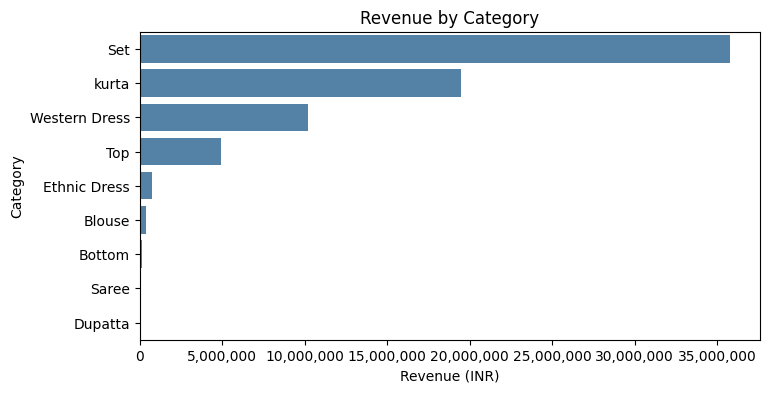

In [40]:
# Horizontal bar chart of revenue by category, ranked from highest to lowest
plt.figure(figsize=(8,4))
sns.barplot(data=cat, x='Revenue', y='Category', order=cat['Category'], color='steelblue')
plt.title('Revenue by Category')
plt.xlabel('Revenue (INR)')
plt.ylabel('Category')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.show()

Revenue is heavily concentrated in Set and kurta. Inventory and promotion should focus on Set, kurta and Western Dress, and the long tail should be reviewed for range cuts.

In [41]:
# Top 10 styles by revenue (non-cancelled only)
top_styles = sales.groupby('Style').agg(
    Revenue = ('Amount', 'sum'),
    Units = ('Qty', 'sum')
).sort_values('Revenue',ascending =False).head(10).reset_index()

top_styles

,Style,Revenue,Units
0,JNE3797,2637913.0,3601
1,J0230,1793265.0,1606
2,SET268,1192006.0,1601
3,J0341,1153249.0,1397
4,J0003,880378.0,1341
5,JNE3405,774231.0,1936
6,J0008,754804.0,705
7,SET345,668876.0,1067
8,SET278,658473.0,458
9,SET324,651227.0,1092


JNE3797 is the top style at about 2.64M (about 3.7% of revenue). The top 10 styles together bring only about 15.6% of revenue, so sales are spread across many styles and don't depend on a few bestsellers.
J0008 earns about 755K from only 705 units, which means a high price per unit (about 1,070), while JNE3405 sells 1,936 units at about 400 each.

# average order value by month, which completes the AOV point from the brief.

In [42]:
# Average order value per month, to see whether customers spend more or less per order
monthly['AOV'] = (monthly['Revenue']/monthly['Orders']).round(2)
monthly

,Month,Month_Name,Revenue,Orders,AOV
0,3,March,95415.00,140,681.54
1,4,April,26284149.62,39121,671.87
2,5,May,23986391.00,33725,711.23
3,6,June,21420218.00,30172,709.94


# weekday pattern. The question this answers: which days get the most orders?

In [43]:
# Orders and revenue by weekday (non-cancelled only), in calendar order
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday = sales.groupby('Weekday').agg(
    Revenue = ('Amount', 'sum'),
    Orders = ('Order ID', 'nunique')
).reindex(day_order).reset_index()
weekday

,Weekday,Revenue,Orders
0,Monday,10301915.00,14805
1,Tuesday,10491683.00,15049
2,Wednesday,10318712.00,14960
3,Thursday,9492349.00,13733
4,Friday,9863886.00,14154
5,Saturday,10304962.62,14775
6,Sunday,11012666.00,15682


Sunday brings the most orders (15,682) and revenue (11.01M). Thursday is the lowest, with about 14% less revenue than Sunday (9.49M vs 11.01M). Friday is also lower (9.86M). Monday, Tuesday, Wednesday and Saturday are very close (about 10.3M to 10.5M), so there is no strong weekly pattern. Promotions could target Thursday and Friday.

# Customer theme, starting with top locations. The question this answers: which states bring in the most sales?

In [44]:
# Checking whether the same state is spelled in different ways (capitals or spaces)
print('Before:', df['ship-state'].nunique())
print('After', df['ship-state'].str.strip().str.upper().nunique())

Before: 70
After 48


In [45]:
# Same state was spelled with different capitals/spaces, so standardising to upper case
df['ship-state'] = df['ship-state'].str.strip().str.upper()
sales = df[~df['Is_Cancelled']]           # rebuilding sales so it uses the cleaned column

print(df['ship-state'].nunique())
print(df['ship-state'].nunique())

48
48


In [46]:
# Listing all state names to spot spelling variants of the same state
sorted(df['ship-state'].unique())

['ANDAMAN & NICOBAR',
 'ANDHRA PRADESH',
 'APO',
 'AR',
 'ARUNACHAL PRADESH',
 'ASSAM',
 'BIHAR',
 'CHANDIGARH',
 'CHHATTISGARH',
 'DADRA AND NAGAR',
 'DELHI',
 'GOA',
 'GUJARAT',
 'HARYANA',
 'HIMACHAL PRADESH',
 'JAMMU & KASHMIR',
 'JHARKHAND',
 'KARNATAKA',
 'KERALA',
 'LADAKH',
 'LAKSHADWEEP',
 'MADHYA PRADESH',
 'MAHARASHTRA',
 'MANIPUR',
 'MEGHALAYA',
 'MIZORAM',
 'NAGALAND',
 'NEW DELHI',
 'NL',
 'ODISHA',
 'ORISSA',
 'PB',
 'PONDICHERRY',
 'PUDUCHERRY',
 'PUNJAB',
 'PUNJAB/MOHALI/ZIRAKPUR',
 'RAJASTHAN',
 'RAJSHTHAN',
 'RAJSTHAN',
 'RJ',
 'SIKKIM',
 'TAMIL NADU',
 'TELANGANA',
 'TRIPURA',
 'UNKNOWN',
 'UTTAR PRADESH',
 'UTTARAKHAND',
 'WEST BENGAL']

In [47]:
# Merging misspelled, short and old state names into one standard name each
state_fix = {
    'NEW DELHI': 'DELHI',
    'ORISSA': 'ODISHA',
    'PONDICHERRY': 'PUDUCHERRY',
    'PB': 'PUNJAB',
    'PUNJAB/MOHALI/ZIRAKPUR': 'PUNJAB',
    'RAJSHTHAN': 'RAJASTHAN',
    'RAJSTHAN': 'RAJASTHAN',
    'RJ': 'RAJASTHAN',
    'NL': 'NAGALAND',
    'AR': 'ARUNACHAL PRADESH',
    'APO': 'UNKNOWN'
}
df['ship-state'] = df['ship-state'].replace(state_fix)
sales = df[~df['Is_Cancelled']]   # rebuilding sales so it uses the cleaned column

print(df['ship-state'].nunique())

37


State names had spelling variants (different capitals, short codes like PB, RJ and NL, and old names like Orissa and Pondicherry). After merging them, 36 states/UTs remain, plus UNKNOWN for rows with no valid state (including APO addresses). UNKNOWN is excluded from the ranking.

In [48]:
# Top 10 states by revenue and orders (non-cancelled only); 'UNKNOWN' is excluded
states = sales[sales['ship-state']!= 'UNKNOWN'].groupby('ship-state').agg(
    Revenue = ('Amount', 'sum'),
    Orders = ('Order ID', 'nunique')
).sort_values('Revenue', ascending=False).head(10).reset_index()

states['Revenue_Share_%'] = (states['Revenue'] /sales['Amount'].sum() * 100).round(1)
states

,ship-state,Revenue,Orders,Revenue_Share_%
0,MAHARASHTRA,12234616.00,17997,17.0
1,KARNATAKA,9648629.00,14078,13.4
2,TELANGANA,6294073.57,8900,8.8
3,UTTAR PRADESH,6184815.00,8526,8.6
4,TAMIL NADU,5959537.00,9076,8.3
5,DELHI,4052099.48,5745,5.6
6,KERALA,3378842.00,5019,4.7
7,WEST BENGAL,3208355.00,4804,4.5
8,ANDHRA PRADESH,2887107.00,4163,4.0
9,HARYANA,2655292.00,3614,3.7


Maharashtra (17.0%) and Karnataka (13.4%) bring about 30% of revenue. The top 5 states (adding Telangana, Uttar Pradesh and Tamil Nadu) bring about 56%, and the top 10 about 79%, so sales are concentrated in a few states.
The five southern states in the list (Karnataka, Telangana, Tamil Nadu, Kerala, Andhra Pradesh) together bring about 39% of revenue.
Recommendation: prioritise stock placement, faster delivery and promotions in these top states, and treat the low-ranking states as growth opportunities.

# Top states (which states bring in the most sales?)

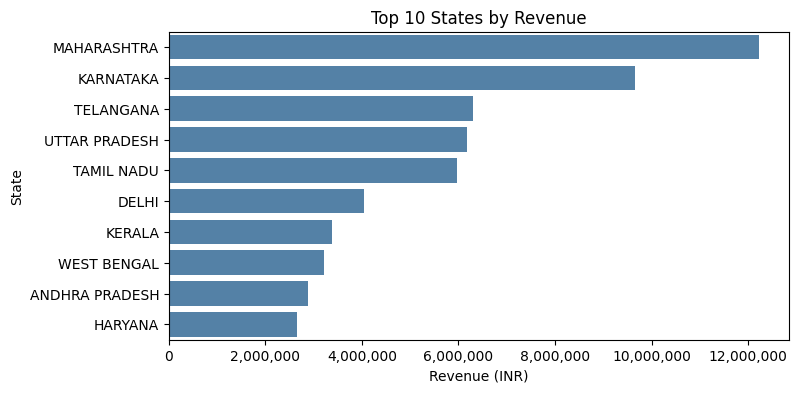

In [49]:
# Bar chart of the top 10 states by revenue, ranked from highest to lowest
plt.figure(figsize=(8,4))
sns.barplot(data=states, x='Revenue', y='ship-state', order=states['ship-state'], color='steelblue')
plt.title('Top 10 States by Revenue')
plt.xlabel('Revenue (INR)')
plt.ylabel('State')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.show()

Maharashtra is the top state with 17% of revenue, followed by Karnataka with 13.4%. The top 5 states bring in about 56% of revenue and the top 10 about 79%, so sales are concentrated in a few states. These are the priority states for stock placement and faster delivery

In [50]:
# Checking for other spellings of the same cities
for name in ['BANGALORE', 'BENGALURU', 'DELHI', 'NEW DELHI', 'GURGAON', 'GURUGRAM', 'BOMBAY', 'MUMBAI']:
  print(name, '->', (df['ship-city']== name).sum())

BANGALORE -> 558
BENGALURU -> 11211
DELHI -> 133
NEW DELHI -> 5793
GURGAON -> 153
GURUGRAM -> 1867
BOMBAY -> 0
MUMBAI -> 6124


In [51]:
# Merging old/alternate city names into one standard name each, then rebuilding the top 10 cities
city_fix = {'BANGALORE': 'BENGALURU', 'DELHI': 'NEW DELHI', 'GURGAON': 'GURUGRAM'}
df['ship-city'] = df['ship-city'].replace(city_fix)
sales = df[~df['Is_Cancelled']]   # rebuilding sales so it uses the cleaned column

cities = sales[sales['ship-city'] != 'UNKNOWN'].groupby('ship-city').agg(
    Revenue=('Amount', 'sum'),
    Orders=('Order ID', 'nunique')
).sort_values('Revenue', ascending=False).head(10).reset_index()
cities['Revenue_Share_%'] = (cities['Revenue'] / sales['Amount'].sum() * 100).round(1)
cities

,ship-city,Revenue,Orders,Revenue_Share_%
0,BENGALURU,6675432.00,9697,9.3
1,HYDERABAD,4500303.57,6350,6.3
2,NEW DELHI,3403973.48,4815,4.7
3,MUMBAI,3400974.00,4976,4.7
4,CHENNAI,2824090.00,4280,3.9
5,PUNE,2153505.00,3126,3.0
6,KOLKATA,1305233.00,1954,1.8
7,GURUGRAM,1230830.00,1700,1.7
8,THANE,918842.00,1383,1.3
9,LUCKNOW,850541.00,1177,1.2


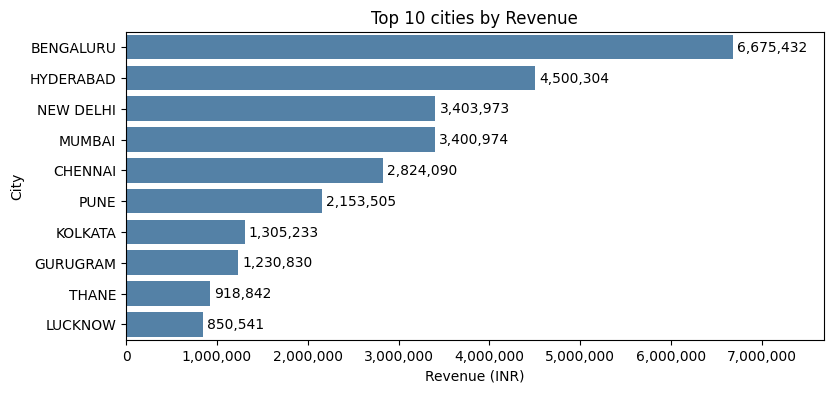

In [52]:
# Bar chart of the top 10 cities by revenue, with value labels on each bar
plt.figure(figsize=(9,4))
ax = sns.barplot(data=cities, x='Revenue', y='ship-city', order=cities['ship-city'], color='steelblue')
ax.bar_label(ax.containers[0], labels = [f'{v:,.0f}' for v in cities['Revenue']], padding=3)
ax.margins(x=0.15)
plt.title('Top 10 cities by Revenue')
plt.xlabel('Revenue (INR)')
plt.ylabel('City')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.show()

Bengaluru is the top city with 9.3% of revenue (6.68M), followed by Hyderabad (6.3%), New Delhi (4.7%) and Mumbai (4.7%). The top 10 cities bring in about 38% of revenue, so sales are spread across many cities, unlike states where the top 10 gave about 79%. Three of the top five cities (Bengaluru, Hyderabad, Chennai) are in South India, so these metros are the first choice for faster delivery and local promotions. Some rare spelling variants may remain in the city names.

# cancellation trends. The question this answers: are cancellations rising, and how big a problem are they?

In [53]:
# Cancellation rate overall and by month (all orders, March excluded because it has one day only)
print(f"Overall cancellation rate: {df['Is_Cancelled'].mean() * 100:.1f}%")

cancel_month = df[df['Month'] != 3].groupby(['Month', 'Month_Name']).agg(
    Rows = ('Is_Cancelled', 'size'),
    Cancelled = ('Is_Cancelled', 'sum')
).reset_index()

cancel_month['Cancel_Rate_%'] = (cancel_month['Cancelled'] / cancel_month['Rows']*100).round(1)
cancel_month

Overall cancellation rate: 14.2%


,Month,Month_Name,Rows,Cancelled,Cancel_Rate_%
0,4,April,49056,7137,14.5
1,5,May,42032,5880,14.0
2,6,June,37684,5303,14.1


The overall cancellation rate is 14.2% per order line, and it stays almost the same from April (14.5%) to June (14.1%). So cancellations are not the reason revenue is falling. The fall comes from fewer orders. Even so, about 1 in 7 order lines is cancelled, which is lost revenue and wasted effort, so I will check where cancellations are highest.

In [54]:
# where do cancellations happen? Starting with fulfilment type.
# Cancellation rate by fulfilment type (Amazon vs Merchant)

cancel_fulfilment = df.groupby('Fulfilment', observed = True).agg(
    Rows= ('Is_Cancelled','size'),
    Cancelled = ('Is_Cancelled','sum')
).reset_index()

cancel_fulfilment['Cancel_Rate_%'] = (cancel_fulfilment['Cancelled']/ cancel_fulfilment['Rows']*100).round(1)
cancel_fulfilment


,Fulfilment,Rows,Cancelled,Cancel_Rate_%
0,Amazon,89673,11476,12.8
1,Merchant,39270,6862,17.5


Merchant-fulfilled orders have a cancellation rate of 17.5%, against 12.8% for Amazon-fulfilled orders. Merchant handles about 31% of order lines but accounts for about 37% of cancellations. Improving merchant order processing, for example stock accuracy and faster dispatch, could recover revenue.

# B2B vs B2C. The question this answers: do business buyers behave differently from regular customers?

In [55]:
# B2B vs B2C comparison: revenue, orders, average order value, units per order and cancellation rate
b2b = df.groupby('Order_Type').agg(
    Rows = ('Order ID', 'size'),
    Cancelled = ('Is_Cancelled', 'sum')
)
b2b['Cancel_Rate_%'] = (b2b['Cancelled']/ b2b['Rows']*100).round(1)

sales_b2b = sales.groupby('Order_Type').agg(
    Revenue=('Amount', 'sum'),
    Orders=('Order ID', 'nunique'),
    Units=('Qty', 'sum')
)

sales_b2b['AOV'] = (sales_b2b['Revenue'] / sales_b2b['Orders']).round(2)
sales_b2b['Units_per_Order'] = (sales_b2b['Units'] / sales_b2b['Orders']).round(2)

b2b.join(sales_b2b)


,Rows,Cancelled,Cancel_Rate_%,Revenue,Orders,Units,AOV,Units_per_Order
Order_Type,,,,,,,,
B2B,871,73,8.4,560005.00,728,813,769.24,1.12
B2C,128072,18265,14.3,71226168.62,102430,110157,695.36,1.08


B2B orders are less than 1% of revenue (728 orders), so B2C is the core of the business. B2B orders have a higher average order value (769 against 695) and a lower cancellation rate (8.4% against 14.3%), but the sample is small, so these differences should be read with care. B2B looks like a small but valuable segment that could be grown with targeted offers.

# Logistics

The question this answers: how do Amazon and Merchant fulfilment compare?

In [56]:
# Are Merchant orders the same as Easy Ship orders?
print(pd.crosstab(df['Fulfilment'], df['fulfilled-by']))
#  Fulfilment comparison on non-cancelled orders
ful = sales.groupby('Fulfilment', observed = True).agg(
    Revenue = ('Amount', 'sum'),
    Orders = ('Order ID', 'nunique')
)
ful['AOV'] = (ful['Revenue']/ ful['Orders']).round(2)
ful['Revenue_Share_%'] = (ful['Revenue']/ ful['Revenue'].sum()*100).round(1)
ful



fulfilled-by  Easy Ship  No easy ship
Fulfilment                           
Amazon                0         89673
Merchant          39270             0


,Revenue,Orders,AOV,Revenue_Share_%
Fulfilment,,,,
Amazon,50703370.00,73172,692.93,70.6
Merchant,21082803.62,29986,703.09,29.4


In [57]:
# Cancellation rate by service level
cancel_service = df.groupby('ship-service-level', observed =True).agg(
    Rows= ('Is_Cancelled', 'size'),
    Cancelled = ('Is_Cancelled', 'sum')
).reset_index()

cancel_service['Cancel_Rate_%'] = (cancel_service['Cancelled']/cancel_service['Rows'] * 100 ).round(1)
cancel_service

,ship-service-level,Rows,Cancelled,Cancel_Rate_%
0,Expedited,88590,11428,12.9
1,Standard,40353,6910,17.1


Standard shipping is cancelled about 33% more often than Expedited.
Standard has about 31% of the order lines but about 38% of all cancellations.
These rates (17.1% and 12.9%) are almost the same as Merchant (17.5%) and Amazon (12.8%). That suggests the two groups overlap, so Standard may be mostly Merchant orders, and the real cause may be fulfilment, not shipping speed.

In [58]:
# are Standard orders mostly Merchant?
print(pd.crosstab(df['ship-service-level'], df['Fulfilment']))

Fulfilment          Amazon  Merchant
ship-service-level                  
Expedited            88590         0
Standard              1083     39270


Merchant and Standard are almost the same group
Merchant orders cancel more often, and the data doesn’t point to shipping speed as the cause.
The recommendation: look at merchant order processing and stock accuracy.

In [59]:
# ship-service-level comparison on non-cancelled orders
ship_sl = sales.groupby('ship-service-level', observed = True).agg(
    Revenue = ('Amount', 'sum'),
    Orders = ('Order ID', 'nunique')
)
ship_sl['AOV'] = (ship_sl['Revenue']/ ship_sl['Orders']).round(2)
ship_sl['Revenue_Share_%'] = (ship_sl['Revenue']/ ship_sl['Revenue'].sum()*100).round(1)
ship_sl

,Revenue,Orders,AOV,Revenue_Share_%
ship-service-level,,,,
Expedited,50594349.00,72139,701.35,70.5
Standard,21191824.62,31019,683.19,29.5


Expedited brings about 70% of revenue and Standard about 30%, the same as the fulfilment split
AOV is slightly higher for Expedited
Shipping level and fulfilment type are almost the same grouping here.

In [60]:
# what share of orders are delivered, in transit, returned or cancelled?
order_share = (df['Status'].value_counts(normalize=True)*100).round(1)
order_share

,proportion
Status,
Shipped,60.3
Shipped - Delivered to Buyer,22.3
Cancelled,14.2
Shipped - Returned to Seller,1.5
Shipped - Picked Up,0.8
Pending,0.5
Pending - Waiting for Pick Up,0.2
Shipped - Returning to Seller,0.1
Shipped - Out for Delivery,0.0


Most orders are shipped or delivered, and cancellations (14.2%) are the biggest problem, not lost or damaged parcels
Returns are only about 1.6%
The dataset has no ship or delivery dates, so average shipping time can’t be calculated.

# product

In [61]:
# which sizes are in highest demand, so stock can be planned?
pro_by_size = sales.groupby(['Size'], observed=True).agg(
    Revenue = ('Amount', 'sum'),
    Units = ('Qty', 'sum')
).sort_values('Revenue', ascending =False).reset_index()

pro_by_size['Unit_Share_%'] = (pro_by_size['Units'] / pro_by_size['Units'].sum() *100).round(1)

pro_by_size



,Size,Revenue,Units,Unit_Share_%
0,M,12631896.57,19392,17.5
1,L,12080362.00,19029,17.1
2,XL,11392048.00,18072,16.3
3,XXL,9782095.00,15740,14.2
4,S,9670006.57,14530,13.1
5,3XL,8442448.00,12990,11.7
6,XS,6343040.48,9322,8.4
7,6XL,543819.00,665,0.6
8,5XL,400404.00,495,0.4
9,4XL,309112.00,380,0.3


M, L and XL are the top three sizes, with about half of all units
About 90% of units come from six sizes, so stock should be focused there
4XL, 5XL, 6XL and Free make up only about 1.6% of units, so stock very little of them.

In [62]:
# how many units does a typical order contain, and does it affect stock planning?
Units_per_order = sales.groupby('Order_Type').agg(
    Orders=('Order ID', 'nunique'),
    Units=('Qty', 'sum')
)
Units_per_order['Units_per_Order'] = (Units_per_order['Units']/Units_per_order['Orders']).round(2)

Units_per_order

,Orders,Units,Units_per_Order
Order_Type,,,
B2B,728,813,1.12
B2C,102430,110157,1.08


A typical order has about 1.08 units (B2B 1.12, B2C 1.08), so almost every order is a single item. Stock planning should therefore follow item-level demand by size and category, not bulk orders.

In [63]:
# Overall_Average
overall_avg = (sales['Qty'].sum() / sales['Order ID'].nunique()).round(2)
print('overall_avg:', f'{overall_avg}')

overall_avg: 1.08


# Returns

In [64]:
# Rows, cancelled and returned counts per category
cat_Return = df.groupby(['Category'], observed=True).agg(
    Rows = ('IS_Returned', 'size'),
    Cancelled = ('Is_Cancelled', 'sum'),
    Returned = ('IS_Returned', 'sum')
).reset_index()

cat_Return['Cancelled_Rate_%'] = (cat_Return['Cancelled']/ cat_Return['Rows']*100).round(1)
cat_Return['Return_Rate_%'] = (cat_Return['Returned']/ cat_Return['Rows']*100).round(1)

cat_Return.sort_values('Cancelled_Rate_%', ascending=False)

,Category,Rows,Cancelled,Returned,Cancelled_Rate_%,Return_Rate_%
8,kurta,49864,7257,752,14.6,1.5
5,Set,50272,7337,845,14.6,1.7
7,Western Dress,15495,2125,343,13.7,2.2
1,Bottom,440,60,6,13.6,1.4
4,Saree,164,21,1,12.8,0.6
3,Ethnic Dress,1158,146,16,12.6,1.4
0,Blouse,926,116,12,12.5,1.3
6,Top,10621,1276,134,12.0,1.3
2,Dupatta,3,0,0,0.0,0.0


Rates are per order line. Set and kurta have the highest cancellation rate (14.6%), but all the big categories are close (12% to 14.6%). Western Dress has the highest return rate (2.2%), against about 1.3% to 1.7% for the other large categories. Blouse, Bottom, Ethnic Dress, Saree and Dupatta are not interpreted because they have too few order lines to trust. Returns are low overall (about 1.6%), so cancellations are the bigger problem.

Western Dress has the highest return rate (2.2%), so its quality and size guide should be reviewed first. Small sizes (XS, S) have the highest cancellation rates, so stock availability in those sizes should be checked.

In [65]:
# Rows, cancelled and returned counts per Size
size_Return = df.groupby(['Size'], observed=True).agg(
    Rows = ('IS_Returned', 'size'),
    Cancelled = ('Is_Cancelled', 'sum'),
    Returned = ('IS_Returned', 'sum')
).reset_index()

size_Return['Cancelled_Rate_%'] = (size_Return['Cancelled']/ size_Return['Rows']*100).round(1)
size_Return['Return_Rate_%'] = (size_Return['Returned']/ size_Return['Rows']*100).round(1)

size_Return.sort_values('Cancelled_Rate_%', ascending=False)

,Size,Rows,Cancelled,Returned,Cancelled_Rate_%,Return_Rate_%
9,XS,11157,1865,170,16.7,1.5
7,S,17092,2592,291,15.2,1.7
6,M,22703,3373,411,14.9,1.8
5,L,22122,3144,356,14.2,1.6
8,XL,20878,2855,340,13.7,1.6
10,XXL,18089,2419,280,13.4,1.5
4,Free,379,49,4,12.9,1.1
0,3XL,14810,1866,238,12.6,1.6
1,4XL,426,48,4,11.3,0.9
2,5XL,550,55,11,10.0,2.0


Rates are per order line. Small sizes (XS, S) cancel the most, and the rate drops steadily toward 3XL. Returns don't change much by size (about 1.5% to 1.8% for the main sizes). The tiny sizes (4XL, 5XL, 6XL, Free) are not interpreted because the sample is too small. For example, 5XL shows a 2.0% return rate on only 11 returns, which is not reliable.

# Recommendations and Conclusions

# Theme Financial :

*    Findings : Revenue fell about 18.5% from April to June, orders about 22.9%, while AOV rose slightly (about 6%).
*   Win back order volume (promotions, fewer merchant cancellations).

# Theme Financial (Products and Weekdays)	:

*  Findings : Set and kurta bring in about 77% of revenue.
*  Possible recommendation : Keep these two well stocked.
* Findings: Sunday is the strongest day, and Thursday and Friday are the weakest.
* Possible recommendation: Run promotions on Thursday and Friday.



# Theme Customer :

*   Findings : Maharashtra and Karnataka bring in about 30% , Bengaluru is the top city.
*  Possible recommendation : Focus stock and delivery there.
*  Findings: B2B is only about 0.8% of revenue, but its AOV is higher (769 vs 695) and its cancellation rate is lower (8.4% vs 14.3%).
*  Possible recommendation: Test bulk-purchase offers or a business-account programme, since the sample is small.



# Theme Logistics :

*   Findings : Merchant (Standard) cancels 17.5%, against 12.8% for Amazon.
*   Possible recommendation : Improve merchant order processing.



# Theme Products :

*  Findings : M,L and XL are about half of units, and XS cancels  most.
*  Possible recommendations : Stock mid sizes first, check XS availability.


# Theme Returns :

*   Findings : Returns are only about 1.6% , with Western Dress  highest  at 2.2%.
*  Possible recommendations : Check Western Dress quality.


# Conclusions :

*   Set and kurta bring in about 77% of revenue. Maharashtra and Karnataka bring in about 30%
*   Order volume is falling each month while cancellations stay near 14%
* Win back order volume, or reduce merchant cancellations (17.5% against 12.8% for Amazon)

# Limitations :

* No delivery dates in the data, so shipping time couldn't be measured.
* No customer ID, so customer retention and repeat purchases couldn't be measured.
* Only 3 months of data (March has 1 day, June ends on the 29th), so true seasonality can't be judged.
* 7,794 missing Amounts were filled with the median (605). Cancelled orders were excluded from revenue, but about 231 non-cancelled rows carry the median.
* All rates are per order line, and returns are identified from order status.








